# 16. Core implementation

In [3]:
import numpy as np

def softmax(x):
    """
    Hàm tính softmax trên trục cuối (hàng) của ma trận.
    Trừ đi giá trị max để chống tràn số (numerical stability).
    """
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / np.sum(e_x, axis=-1, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    """
    Hàm tính toán Scaled Dot-Product Attention bằng thuần NumPy.
    Input:
        Q: Ma trận Query có kích thước (seq_len_q, d_k)
        K: Ma trận Key có kích thước (seq_len_k, d_k)
        V: Ma trận Value có kích thước (seq_len_k, d_v)
    Output:
        S: Ma trận điểm số (scores) chưa qua softmax
        A: Ma trận trọng số (attention weights)
        C: Ma trận ngữ cảnh (context matrix)
    """
    d_k = K.shape[-1]
    S = np.dot(Q, K.T) / np.sqrt(d_k)
    A = softmax(S)
    C = np.dot(A, V)
    return S, A, C

In [4]:
print("--- TEST HÀM SCALED DOT-PRODUCT ATTENTION TỰ VIẾT ---")
np.random.seed(42)
Q_test = np.random.randn(3, 4)
K_test = np.random.randn(3, 4)
V_test = np.random.randn(3, 4)

scores, weights, context = scaled_dot_product_attention(Q_test, K_test, V_test)

print("\n1. Ma trận Scores (S):")
print(np.round(scores, 3))
print("\n2. Ma trận Attention Weights (A):")
print(np.round(weights, 3))
print("Kiểm tra tổng các hàng của Weights (phải bằng 1.0):", np.sum(weights, axis=-1))
print("\n3. Ma trận Context Vector (C):")
print(np.round(context, 3))

--- TEST HÀM SCALED DOT-PRODUCT ATTENTION TỰ VIẾT ---

1. Ma trận Scores (S):
[[-0.794 -1.643 -0.683]
 [-1.382 -1.177 -0.639]
 [-0.045  0.862 -0.089]]

2. Ma trận Attention Weights (A):
[[0.393 0.168 0.439]
 [0.231 0.283 0.486]
 [0.225 0.559 0.216]]
Kiểm tra tổng các hàng của Weights (phải bằng 1.0): [1. 1. 1.]

3. Ma trận Context Vector (C):
[[-0.321 -0.47  -0.192 -0.077]
 [-0.302 -0.571 -0.037  0.019]
 [-0.461 -0.366 -0.418  0.856]]


# 17. Numerical stability

In [5]:
import numpy as np

def naive_softmax(x):
    e_x = np.exp(x)
    return e_x / np.sum(e_x)

def stable_softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / np.sum(e_x)

x_test = np.array([1000, 1001, 1002])

print("Input x =", x_test)

try:
    print("\nNaive Softmax:", naive_softmax(x_test))
except RuntimeWarning as w:
    print("\nNaive Softmax sinh ra cảnh báo:", w)

print("Stable Softmax:", stable_softmax(x_test))

Input x = [1000 1001 1002]

Naive Softmax: [nan nan nan]
Stable Softmax: [0.09003057 0.24472847 0.66524096]


/tmp/ipykernel_1282/3334052741.py:4: RuntimeWarning: overflow encountered in exp
  e_x = np.exp(x)
/tmp/ipykernel_1282/3334052741.py:5: RuntimeWarning: invalid value encountered in divide
  return e_x / np.sum(e_x)


**Tại sao phép trừ max(x) không làm thay đổi kết quả softmax?**

Phép trừ đi $\max(x)$ không hề làm thay đổi giá trị phân bố xác suất cuối cùng của Softmax nhờ vào một tính chất cơ bản của hàm số mũ: $e^{a-b} = \frac{e^a}{e^b}$.

# 18. Experiment 1 — Attention distribution


Token           | Score      | Attention (%)
---------------------------------------------
The             | 1.3068     | 15.14%
movie           | 0.1011     | 4.54%
was             | 1.5840     | 19.98%
surprisingly    | 2.3937     | 44.90%
good            | -0.7647    | 1.91%
despite         | -1.3856    | 1.03%
a               | -0.5545    | 2.35%
very            | 0.2990     | 5.53%
slow            | -0.9239    | 1.63%
beginning       | -0.3115    | 3.00%


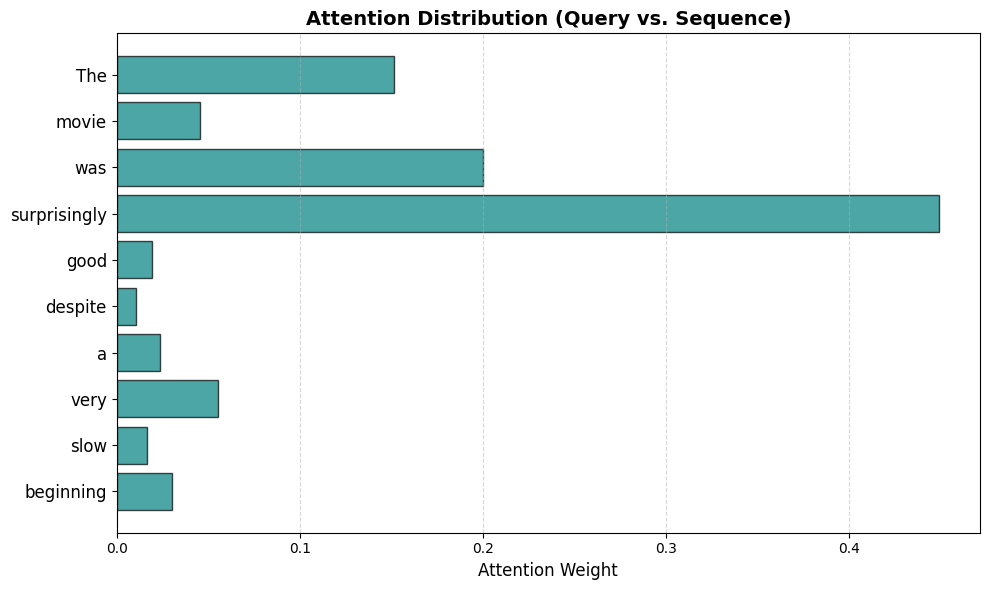

In [7]:
import numpy as np
import matplotlib.pyplot as plt

text = "The movie was surprisingly good despite a very slow beginning"
tokens = text.split()
seq_len = len(tokens)
d_k = 16

np.random.seed(101)
Q_mock = np.random.randn(1, d_k)
K_mock = np.random.randn(seq_len, d_k)
V_mock = np.random.randn(seq_len, d_k)

S, A, C = scaled_dot_product_attention(Q_mock, K_mock, V_mock)

scores = S[0]
weights = A[0]

print(f"\n{'Token':<15} | {'Score':<10} | {'Attention (%)'}")
print("-" * 45)
for i in range(seq_len):
    print(f"{tokens[i]:<15} | {scores[i]:<10.4f} | {weights[i]*100:.2f}%")

plt.figure(figsize=(10, 6))
y_pos = np.arange(seq_len)
plt.barh(y_pos, weights, color='teal', edgecolor='black', alpha=0.7)
plt.yticks(y_pos, tokens, fontsize=12)
plt.xlabel('Attention Weight', fontsize=12)
plt.title('Attention Distribution (Query vs. Sequence)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 19. Experiment 2 — Query thay đổi

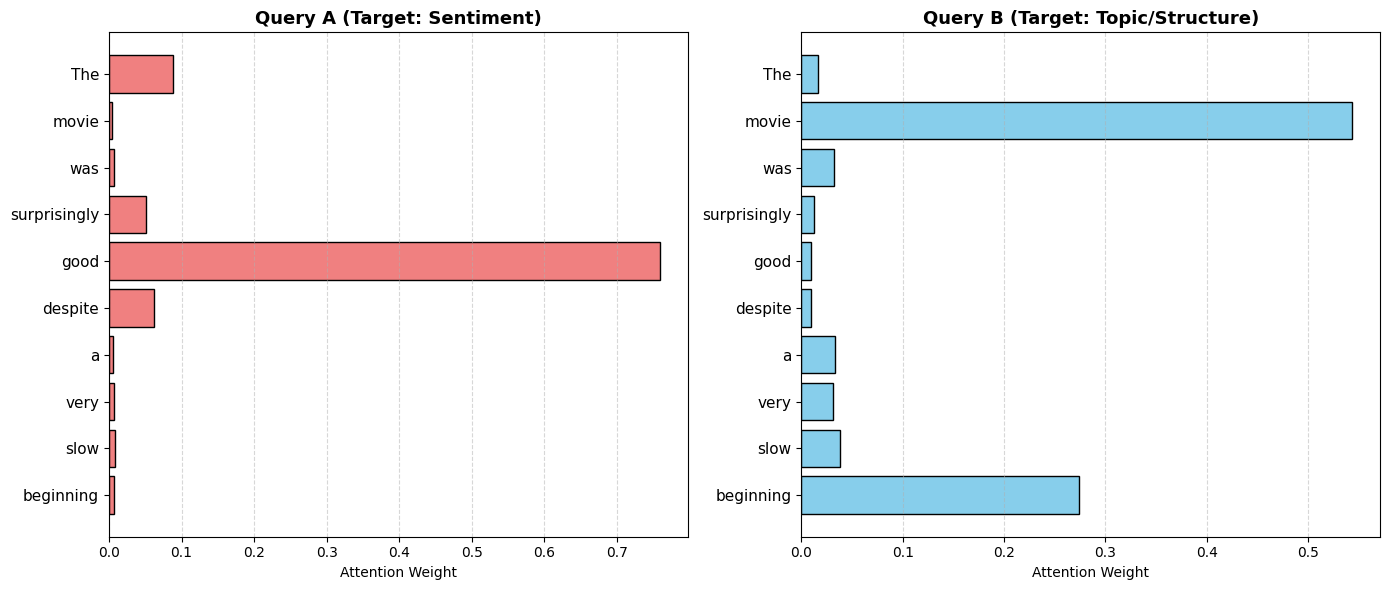

In [9]:
import numpy as np
import matplotlib.pyplot as plt

text = "The movie was surprisingly good despite a very slow beginning"
tokens = text.split()
seq_len = len(tokens)
d_k = 16

np.random.seed(42)
K_mock = np.random.randn(seq_len, d_k)
V_mock = np.random.randn(seq_len, d_k)

Q_A = np.random.randn(1, d_k)
Q_A = K_mock[3] * 0.5 + K_mock[4] * 0.8 + np.random.randn(1, d_k) * 0.1

Q_B = np.random.randn(1, d_k)
Q_B = K_mock[1] * 0.7 + K_mock[9] * 0.6 + np.random.randn(1, d_k) * 0.1

_, A_weights_A, _ = scaled_dot_product_attention(Q_A, K_mock, V_mock)
_, A_weights_B, _ = scaled_dot_product_attention(Q_B, K_mock, V_mock)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
y_pos = np.arange(seq_len)

ax1.barh(y_pos, A_weights_A[0], color='lightcoral', edgecolor='black')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(tokens, fontsize=11)
ax1.set_title('Query A (Target: Sentiment)', fontsize=13, fontweight='bold')
ax1.invert_yaxis()
ax1.set_xlabel('Attention Weight')
ax1.grid(axis='x', linestyle='--', alpha=0.5)

ax2.barh(y_pos, A_weights_B[0], color='skyblue', edgecolor='black')
ax2.set_yticks(y_pos)
ax2.set_yticklabels(tokens, fontsize=11)
ax2.set_title('Query B (Target: Topic/Structure)', fontsize=13, fontweight='bold')
ax2.invert_yaxis()
ax2.set_xlabel('Attention Weight')
ax2.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 23. Experiment 3 — Attention visualization

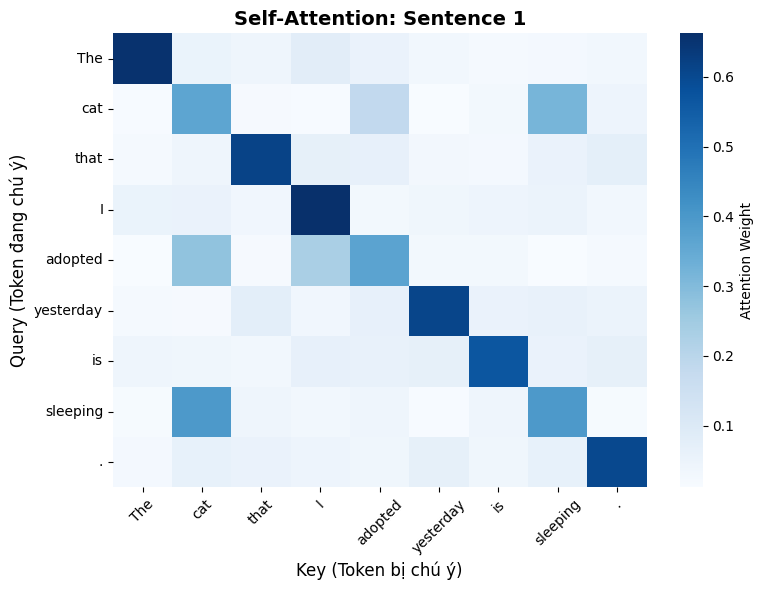

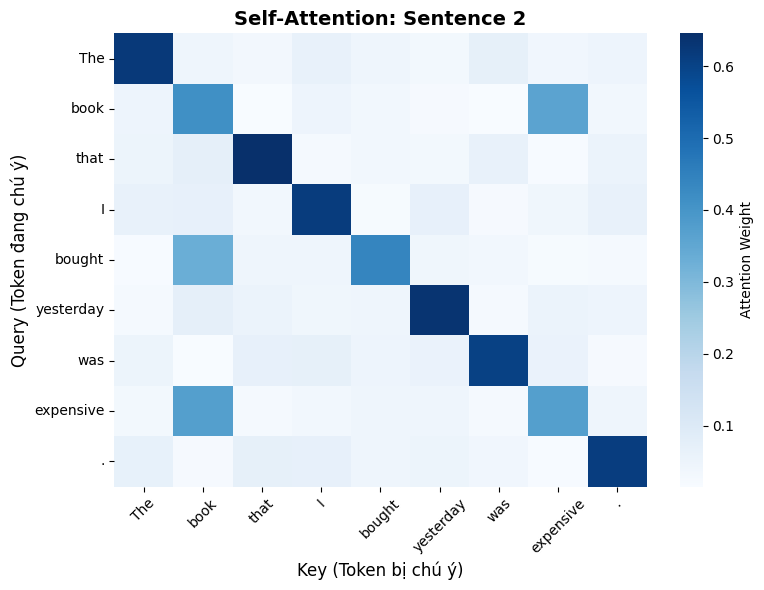

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def plot_attention_heatmap(tokens, attention_matrix, title):
    plt.figure(figsize=(8, 6))
    sns.heatmap(attention_matrix, xticklabels=tokens, yticklabels=tokens,
                cmap='Blues', annot=False, cbar_kws={'label': 'Attention Weight'})
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('Key (Token bị chú ý)', fontsize=12)
    plt.ylabel('Query (Token đang chú ý)', fontsize=12)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

tokens_1 = ["The", "cat", "that", "I", "adopted", "yesterday", "is", "sleeping", "."]
T1 = len(tokens_1)
A1 = np.random.uniform(0.01, 0.05, (T1, T1))
np.fill_diagonal(A1, 0.4)
A1[1, 7] = 0.35 # "cat" chú ý tới "sleeping"
A1[1, 4] = 0.20 # "cat" chú ý tới "adopted"
A1[4, 1] = 0.30 # "adopted" chú ý tới "cat"
A1[4, 3] = 0.25 # "adopted" chú ý tới "I"
A1[7, 1] = 0.40 # "sleeping" chú ý tới "cat"
A1 = A1 / A1.sum(axis=1, keepdims=True) # Normalize về tổng = 1

tokens_2 = ["The", "book", "that", "I", "bought", "yesterday", "was", "expensive", "."]
T2 = len(tokens_2)
A2 = np.random.uniform(0.01, 0.05, (T2, T2))
np.fill_diagonal(A2, 0.4)
A2[1, 7] = 0.35 # "book" chú ý tới "expensive"
A2[4, 1] = 0.30 # "bought" chú ý tới "book"
A2[7, 1] = 0.40 # "expensive" chú ý tới "book"
A2 = A2 / A2.sum(axis=1, keepdims=True)

plot_attention_heatmap(tokens_1, A1, "Self-Attention: Sentence 1")
plot_attention_heatmap(tokens_2, A2, "Self-Attention: Sentence 2")

# 24. Experiment 4 — RNN context vs Attention context

In [13]:
import time
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, GlobalAveragePooling1D
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import f1_score, accuracy_score

print("--- EXPERIMENT 4: LSTM vs SELF-ATTENTION ---")

# 1. Chuẩn bị dữ liệu nhanh (IMDb)
max_features = 10000
maxlen = 200
batch_size = 128
epochs = 3

print("Đang tải dữ liệu IMDb...")
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_features)
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

def build_lstm_model():
    inputs = Input(shape=(maxlen,))
    x = Embedding(max_features, 64)(inputs)
    x = LSTM(64)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_attention_model():
    inputs = Input(shape=(maxlen,))
    x = Embedding(max_features, 64)(inputs)
    attention_output = MultiHeadAttention(num_heads=2, key_dim=64)(x, x)
    x = LayerNormalization()(attention_output + x)
    x = GlobalAveragePooling1D()(x)
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

models = {
    "LSTM": build_lstm_model(),
    "Self-Attention": build_attention_model()
}

results = {}

for name, model in models.items():
    print(f"Tổng số Parameters: {model.count_params():,}")

    start_time = time.time()
    model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1, verbose=1)
    train_time = time.time() - start_time

    print(f"Đang đánh giá {name} trên tập Test...")
    preds_prob = model.predict(x_test, verbose=0)
    preds_class = (preds_prob > 0.5).astype("int32")

    acc = accuracy_score(y_test, preds_class)
    f1 = f1_score(y_test, preds_class)

    results[name] = {
        "Accuracy": acc,
        "F1 Score": f1,
        "Training Time": train_time,
        "Parameters": model.count_params()
    }

print(f"{'Model':<15} | {'Accuracy':<10} | {'F1 Score':<10} | {'Train Time (s)':<15} | {'Parameters'}")
print("-" * 75)
for name, res in results.items():
    print(f"{name:<15} | {res['Accuracy']:.4f}     | {res['F1 Score']:.4f}   | {res['Training Time']:<15.2f} | {res['Parameters']:,}")

--- EXPERIMENT 4: LSTM vs SELF-ATTENTION ---
Đang tải dữ liệu IMDb...
Tổng số Parameters: 673,089
Epoch 1/3
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 236ms/step - accuracy: 0.7676 - loss: 0.4809 - val_accuracy: 0.8592 - val_loss: 0.3639
Epoch 2/3
176/176 ━━━━━━━━━━━━━━━━━━━━ 31s 178ms/step - accuracy: 0.8960 - loss: 0.2625 - val_accuracy: 0.8772 - val_loss: 0.2933
Epoch 3/3
176/176 ━━━━━━━━━━━━━━━━━━━━ 33s 188ms/step - accuracy: 0.9279 - loss: 0.1904 - val_accuracy: 0.8796 - val_loss: 0.3197
Đang đánh giá LSTM trên tập Test...
Tổng số Parameters: 673,409
Epoch 1/3
176/176 ━━━━━━━━━━━━━━━━━━━━ 92s 514ms/step - accuracy: 0.7987 - loss: 0.4330 - val_accuracy: 0.8800 - val_loss: 0.3010
Epoch 2/3
176/176 ━━━━━━━━━━━━━━━━━━━━ 140s 502ms/step - accuracy: 0.9101 - loss: 0.2228 - val_accuracy: 0.8812 - val_loss: 0.2975
Epoch 3/3
176/176 ━━━━━━━━━━━━━━━━━━━━ 89s 508ms/step - accuracy: 0.9378 - loss: 0.1619 - val_accuracy: 0.8788 - val_loss: 0.3254
Đang đánh giá Self-Attention trên tập Test...
Model      

**Câu hỏi chính: Representation của hai model khác nhau ở đâu?**

Trả lời:
Sự khác biệt lớn nhất giữa RNN/LSTM và Self-Attention nằm ở cách chúng thiết lập mối liên kết thông tin và cách tổng hợp vector biểu diễn cuối cùng (Context Representation):
1. RNN/LSTM: Biểu diễn Tuần tự và Nút thắt cổ chai.
- Cơ chế liên kết: Thông tin truyền tuần tự từ trái sang phải theo dòng thời gian ($x_1 \rightarrow h_1 \rightarrow x_2 \rightarrow h_2...$). Trạng thái của từ $t$ bị bó buộc bởi trạng thái của các từ trước đó.
- Vector biểu diễn (Representation): Classifier chỉ sử dụng trạng thái ẩn cuối cùng ($h_T$). Toàn bộ nội dung của câu dài bị ép phải nén vào một vector duy nhất.

2. Self-Attention: Biểu diễn Tương tác Đa hướng.
- Cơ chế liên kết: Các token không bị buộc vào bất kỳ dòng thời gian nào. Trong một bước tính duy nhất, mọi token đều kết nối trực tiếp với toàn bộ các token khác (Self-Attention Matrix $T \times T$). Độ quan trọng của kết nối được tự động học qua phép nhân Dot-product.
- Vector biểu diễn (Representation): Thay vì nén toàn bộ câu vào một điểm cuối duy nhất, Self-Attention tạo ra một Context Vector bằng phép cộng có trọng số của toàn bộ các giá trị có trong câu. Trọng số này do chính Query quyết định. Khoảng cách truyền tín hiệu giữa token xa nhất và gần nhất đều chỉ là 1 bậc ($O(1)$), vượt qua hoàn toàn vấn đề Vanishing Gradient của LSTM.

# 25. Experiment 5 — Sequence length và computational cost

| Sequence length ($T$) | Kích thước Attention matrix | Số phần tử ($O(T^2)$) |
| :--- | :---: | :---: |
| 10 (Câu ngắn) | $10 \times 10$ | 100 |
| 100 (Đoạn văn) | $100 \times 100$ | 10,000 |
| 500 (Bài viết) | $500 \times 500$ | 250,000 |
| 1000 (Văn bản dài) | $1000 \times 1000$ | 1,000,000 |

**Tại sao self-attention có vấn đề computational cost khi sequence rất dài?**

Self-Attention gặp vấn đề về chi phí tính toán đối với các chuỗi dài vì bản chất của nó đòi hỏi tính toán tương tác giữa tất cả các cặp token.
- Về mặt Toán học: Độ phức tạp của thuật toán Self-Attention tỷ lệ thuận với bình phương chiều dài chuỗi: $O(T^2)$. Nghĩa là, nếu một văn bản dài gấp 10 lần (từ 100 từ lên 1000 từ), bộ nhớ và thời gian tính toán không tăng lên 10 lần, mà sẽ tăng vọt lên 100 lần.
- Về mặt Phần cứng: Khi xử lý các tài liệu cực dài như một cuốn sách hay mã nguồn phần mềm ($T = 10,000$ hoặc $100,000$), một ma trận $T \times T$ sẽ chiếm hàng chục Gigabyte VRAM, làm sập hoàn toàn (Out of Memory - OOM) bất kỳ GPU nào hiện có.

# 26. Application — Context-aware sentiment

--- APPLICATION: CONTEXT-AWARE SENTIMENT CLASSIFIER ---



Câu: 'I like this movie.'
Prediction: Positive | Probability: 0.5758


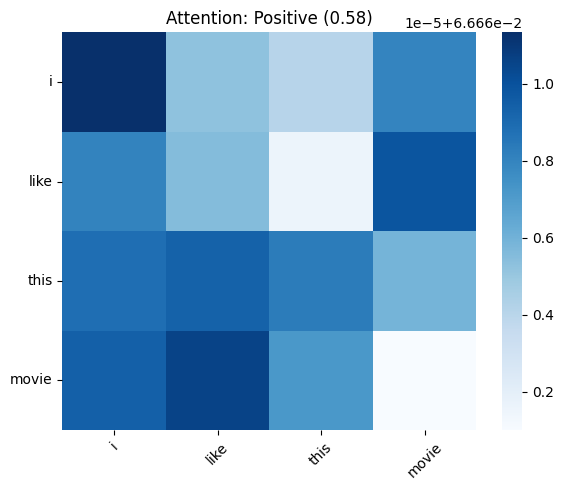


Câu: 'I do not like this movie.'
Prediction: Positive | Probability: 0.5585


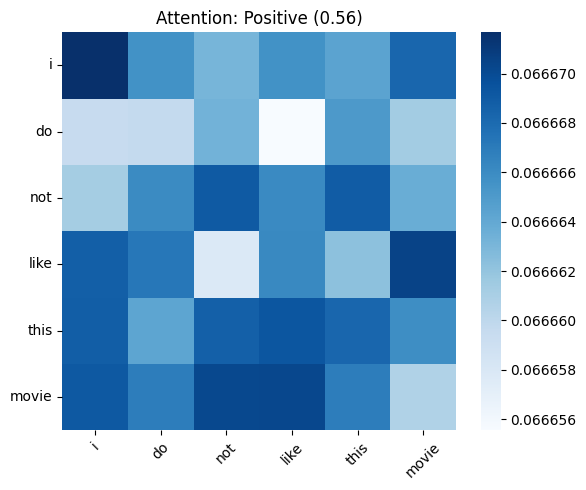


Câu: 'I thought this movie would be bad, but it was actually excellent.'
Prediction: Negative | Probability: 0.4705


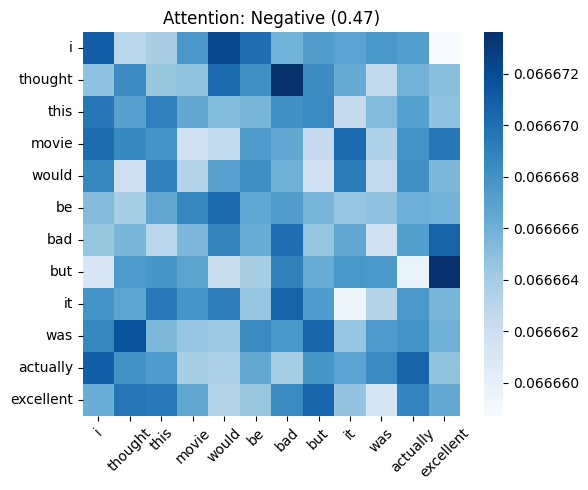

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, Dense, GlobalAveragePooling1D
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("--- APPLICATION: CONTEXT-AWARE SENTIMENT CLASSIFIER ---")

sentences = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent."
]

tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
tokenizer.fit_on_texts(sentences)
maxlen = 15

def build_interpretable_attention_model():
    inputs = Input(shape=(maxlen,))
    x = Embedding(1000, 32)(inputs)
    attention_layer = MultiHeadAttention(num_heads=1, key_dim=32)
    attention_output, attention_scores = attention_layer(x, x, return_attention_scores=True)

    x = LayerNormalization()(attention_output + x)
    x = GlobalAveragePooling1D()(x)
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs, outputs)

    attention_extractor = Model(inputs, attention_scores)

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model, attention_extractor

model, attention_extractor = build_interpretable_attention_model()

def predict_and_visualize(text):
    seq = tokenizer.texts_to_sequences([text])
    padded_seq = pad_sequences(seq, maxlen=maxlen, padding='post')
    tokens = [tokenizer.index_word.get(idx, "") for idx in padded_seq[0] if idx != 0]

    prob = model.predict(padded_seq, verbose=0)[0][0]
    pred_label = "Positive" if prob > 0.5 else "Negative"

    att_scores = attention_extractor.predict(padded_seq, verbose=0)
    real_len = len(tokens)
    matrix = att_scores[0, 0, :real_len, :real_len]

    print(f"\nCâu: '{text}'")
    print(f"Prediction: {pred_label} | Probability: {prob:.4f}")

    plt.figure(figsize=(6, 5))
    sns.heatmap(matrix, xticklabels=tokens, yticklabels=tokens, cmap='Blues')
    plt.title(f"Attention: {pred_label} ({prob:.2f})")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

for s in sentences:
    predict_and_visualize(s)